# 03 · Trends, seasonality and the WHO guidelines

**Questions:**
1. How have PM10, PM2.5 and NO2 changed from 2015 to 2025?
2. What are the seasonal (month), weekly (day) and daily (hour) patterns?
3. How do Milan's levels compare with the WHO 2021 air quality guidelines?

We use complete years 2015–2025 only; 2026 is partial and provisional.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import STL
from src.config import DATA_PROCESSED, POLLUTANTS, WHO_ANNUAL, WHO_DAILY, EU_PM10_DAILY_LIMIT, EU_PM10_MAX_EXCEEDANCE_DAYS, UNIT
from src.analysis import annual_means, theil_sen_trend, pct_change
from src.plotting import set_style, add_source, save, COLORS, GREY, LIGHT_GREY, WHO_COLOR
set_style()

city = pd.read_parquet(DATA_PROCESSED / "daily_city.parquet")
station = pd.read_parquet(DATA_PROCESSED / "daily_station.parquet")
city = city[city.index < "2026-01-01"]
station = station[station["date"] < "2026-01-01"]

## 1. Long-term trend

**Method.** For each year we compute the annual mean of the daily city values (only if ≥ 75% of days are valid). Then we fit a **Theil–Sen** trend: it takes the median of the slopes between every pair of years, so a single unusual year (for example 2020) cannot pull the line much. A **Kendall tau** test checks whether the decline is consistent rather than random.

In [2]:
annual, coverage = annual_means(city)
print("lowest yearly coverage:", coverage.min().round(2).to_dict())
annual.round(1)

lowest yearly coverage: {'PM10': 0.98, 'PM2.5': 0.83, 'NO2': 1.0}


,PM10,PM2.5,NO2
date,,,
2015,40.6,30.3,58.5
2016,35.4,27.8,54.7
2017,39.9,28.1,53.7
2018,32.7,23.0,46.9
2019,30.8,21.2,43.6
2020,33.1,24.2,39.2
2021,31.3,22.0,39.3
2022,33.4,23.5,38.0
2023,27.0,18.7,34.9


In [3]:
trend = pd.DataFrame({p: theil_sen_trend(annual[p]) for p in POLLUTANTS}).T
trend["change_2015_2025_%"] = [pct_change(annual.loc[2025, p], annual.loc[2015, p]) for p in POLLUTANTS]
trend.round(3)

,slope_per_year,ci_low,ci_high,kendall_tau,p_value,change_2015_2025_%
PM10,-1.272,-1.970,-0.571,-0.673,0.003,-36.357
PM2.5,-1.065,-1.526,-0.485,-0.636,0.006,-35.344
NO2,-2.639,-3.201,-1.977,-0.964,0.000,-45.090


All three pollutants decline clearly and consistently (Kendall p < 0.01, and no 95% confidence interval includes zero). NO2 falls fastest, by about 2.6 µg/m³ per year.

Comparing the two end years is sensitive to the weather in those particular years, so the Theil–Sen slope is the more reliable summary. The 2015 → 2025 change is shown because it is easy to communicate.

The chart below shows each station as a thin grey line and the city average in colour, with the WHO annual guideline as a dashed red line.

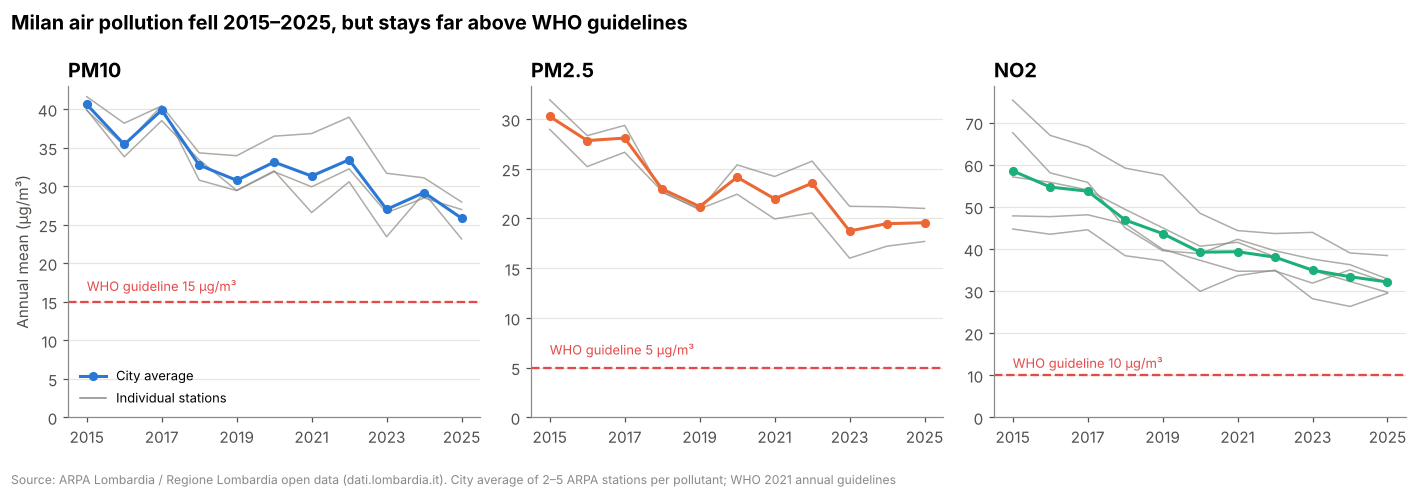

In [4]:
st_annual = (station.assign(year=station["date"].dt.year)
             .groupby(["pollutant", "station", "year"])["valore"].mean())

fig, axes = plt.subplots(1, 3, figsize=(13, 4.2), sharex=True)
for ax, p in zip(axes, POLLUTANTS):
    for st_name, s in st_annual[p].groupby(level="station"):
        ax.plot(s.index.get_level_values("year"), s.values, color=LIGHT_GREY, lw=1, alpha=0.7)
    ax.plot(annual.index, annual[p], color=COLORS[p], marker="o", ms=5, label="City average")
    ax.axhline(WHO_ANNUAL[p], color=WHO_COLOR, ls="--", lw=1.5)
    ax.text(2015, WHO_ANNUAL[p] + 1, f"WHO guideline {WHO_ANNUAL[p]} {UNIT}", color=WHO_COLOR, fontsize=8.5, va="bottom")
    ax.set_title(p, loc="left")
    ax.set_ylim(0, None)
    ax.set_xticks(range(2015, 2026, 2))
axes[0].set_ylabel(f"Annual mean ({UNIT})")
axes[0].plot([], [], color=LIGHT_GREY, lw=1, label="Individual stations")
axes[0].legend(loc="lower left", fontsize=8.5)
fig.suptitle("Milan air pollution fell 2015–2025, but stays far above WHO guidelines", x=0.01, ha="left", fontweight="bold", fontsize=13)
fig.tight_layout()
add_source(fig, "City average of 2–5 ARPA stations per pollutant; WHO 2021 annual guidelines")
save(fig, "01_annual_trends")
plt.show()

**STL decomposition.** To see the trend inside the very strong seasonal swings, we split the monthly means into *trend + seasonal + remainder* with STL (Seasonal-Trend decomposition using LOESS, `robust=True` so outlier months have less influence).

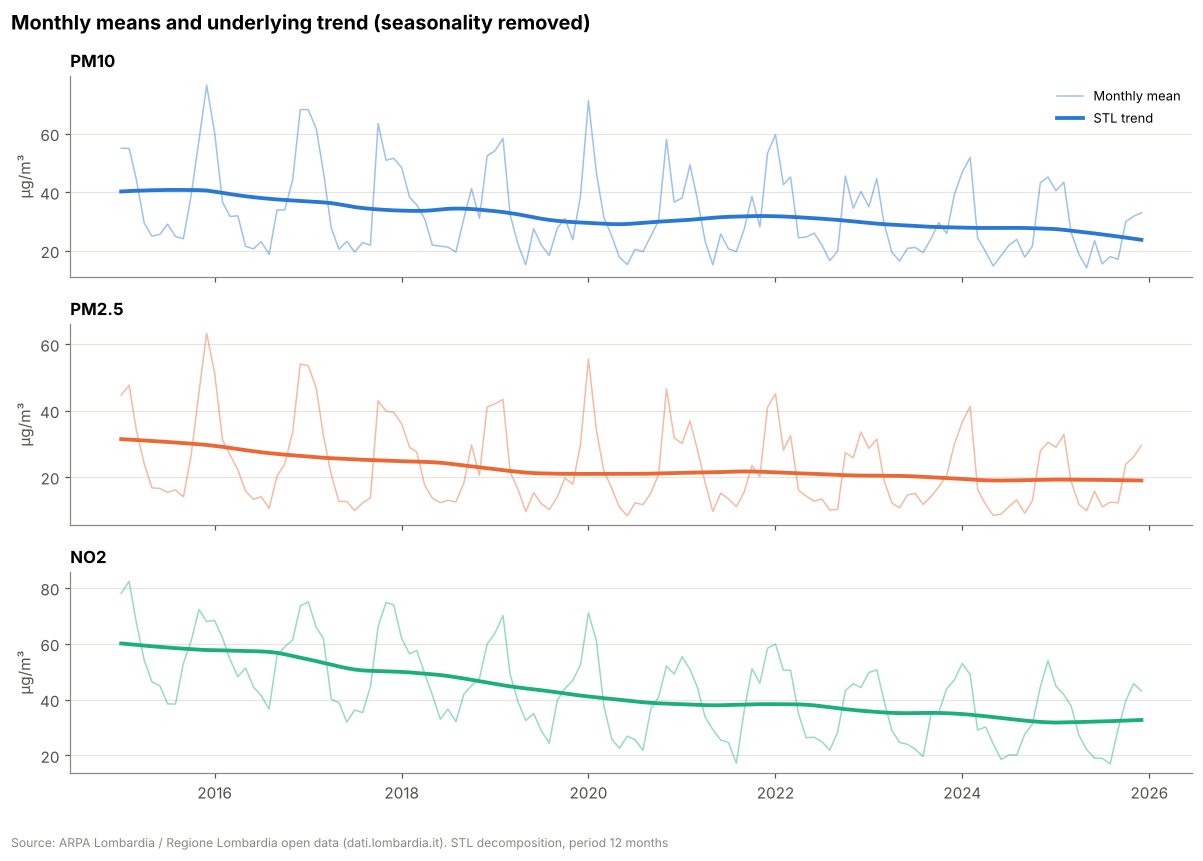

,PM10,PM2.5,NO2
Jan 2015,40.2,31.4,60.1
Dec 2025,23.7,18.9,32.7


In [5]:
monthly = city.resample("MS").mean()
fig, axes = plt.subplots(3, 1, figsize=(11, 7.5), sharex=True)
stl_trend = {}
for ax, p in zip(axes, POLLUTANTS):
    res = STL(monthly[p].interpolate(), period=12, robust=True).fit()
    stl_trend[p] = res.trend
    ax.plot(monthly.index, monthly[p], color=COLORS[p], lw=1, alpha=0.45, label="Monthly mean")
    ax.plot(res.trend.index, res.trend, color=COLORS[p], lw=2.5, label="STL trend")
    ax.set_ylabel(UNIT)
    ax.set_title(p, loc="left", fontsize=11)
axes[0].legend(loc="upper right", fontsize=8.5)
fig.suptitle("Monthly means and underlying trend (seasonality removed)", x=0.01, ha="left", fontweight="bold", fontsize=13)
fig.tight_layout()
add_source(fig, "STL decomposition, period 12 months")
save(fig, "stl_trends")
plt.show()
pd.DataFrame({p: [stl_trend[p].iloc[0], stl_trend[p].iloc[-1]] for p in POLLUTANTS}, index=["Jan 2015", "Dec 2025"]).round(1)

## 2. Seasonal pattern (month of year)

In [6]:
by_month = city.groupby(city.index.month).mean()
ratio = (by_month.max() / by_month.min()).round(1)
print("highest month / lowest month:", ratio.to_dict())
by_month.round(1)

highest month / lowest month: {'PM10': 2.8, 'PM2.5': 3.5, 'NO2': 2.4}


,PM10,PM2.5,NO2
date,,,
1,52.4,41.3,61.9
2,48.0,36.6,58.2
3,35.1,25.0,48.2
4,24.8,17.0,37.4
5,18.8,11.9,32.7
6,22.5,13.2,30.0
7,21.4,12.7,28.9
8,20.1,12.1,25.8
9,24.5,14.3,38.9


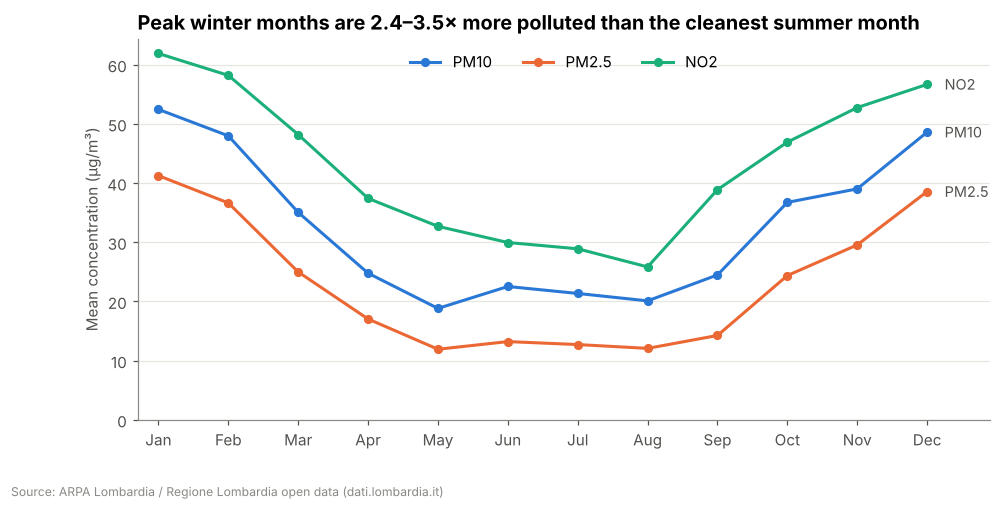

In [7]:
fig, ax = plt.subplots(figsize=(10, 4.5))
months = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
for p in POLLUTANTS:
    ax.plot(range(1, 13), by_month[p], color=COLORS[p], marker="o", ms=5, label=p)
    ax.text(12.25, by_month[p].iloc[-1], p, color=GREY, va="center", fontsize=9.5)
ax.set_xticks(range(1, 13), months)
ax.set_xlim(0.7, 12.9)
ax.set_ylim(0, None)
ax.set_ylabel(f"Mean concentration ({UNIT})")
ax.set_title("Peak winter months are 2.4–3.5× more polluted than the cleanest summer month")
ax.legend(loc="upper center", ncols=3)
add_source(fig)
save(fig, "02_seasonal_cycle")
plt.show()

**Why winter?** The Po Valley is surrounded by the Alps and Apennines, so wind is weak. In winter, cold air near the ground is trapped under warmer air above (a *temperature inversion*) and the mixing layer is shallow, so pollutants accumulate. Domestic heating adds emissions, and secondary particles (e.g. ammonium nitrate, formed from agricultural ammonia and NOx) form more easily in cold, humid air. In summer, a deeper mixing layer and more rain dilute everything.

This is general atmospheric science, not something this dataset proves. The data shows *that* winter is worse, not *why*.

## 3. Weekly pattern (day of week)

To remove the seasonal effect, we compare each day with the mean of its own week, then average these relative differences.

In [8]:
week_mean = city.groupby(city.index.to_period("W")).transform("mean")
rel = (city / week_mean - 1) * 100
dow = rel.groupby(city.index.day_of_week).mean()
dow.index = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
dow.round(1)

,PM10,PM2.5,NO2
Mon,-4.3,-4.5,-0.5
Tue,2.4,-0.2,4.5
Wed,3.1,1.4,6.4
Thu,5.4,4.2,7.2
Fri,5.5,4.0,6.8
Sat,-0.8,0.6,-5.4
Sun,-11.3,-5.6,-19.1


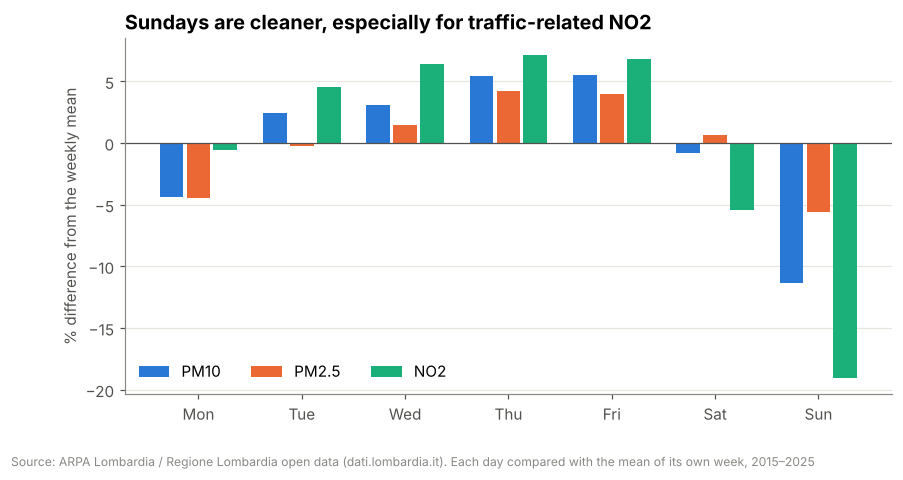

In [9]:
fig, ax = plt.subplots(figsize=(9, 4.2))
x = np.arange(7)
w = 0.26
for i, p in enumerate(POLLUTANTS):
    ax.bar(x + (i - 1) * w, dow[p], width=w - 0.03, color=COLORS[p], label=p)
ax.axhline(0, color=GREY, lw=0.8)
ax.set_xticks(x, dow.index)
ax.set_ylabel("% difference from the weekly mean")
ax.set_title("Sundays are cleaner, especially for traffic-related NO2")
ax.legend(ncols=3, loc="lower left")
add_source(fig, "Each day compared with the mean of its own week, 2015–2025")
save(fig, "03_weekly_cycle")
plt.show()

NO2 shows the strongest weekly cycle. It comes mostly from combustion, especially diesel traffic, which drops on weekends. PM has a weaker cycle because a large part of it is *secondary* (formed in the air over days) or comes from heating and agriculture, which do not follow the working week.

## 4. Daily pattern (hour of day, NO2 only)

Only NO2 is measured hourly. Hours are in ARPA's fixed clock (UTC+1, no daylight saving), so in summer each peak appears one hour earlier than on the wall clock.

In [10]:
hourly = pd.read_parquet(DATA_PROCESSED / "hourly_no2.parquet")
hourly = hourly[hourly["hour_start"] < "2026-01-01"]
hourly["day_type"] = np.where(hourly["hour_start"].dt.day_of_week >= 5, "Weekend", "Weekday")
profile = hourly.groupby(["day_type", hourly["hour_start"].dt.hour])["valore"].mean().unstack(0)
profile.round(1).T

hour_start,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
day_type,,,,,,,,,,,,,,,,,,,,,
Weekday,44.3,40.3,37.1,35.8,36.9,43.7,53.3,57.3,55.5,51.5,...,36.4,37.1,39.6,43.9,48.9,52.8,53.3,52.1,50.8,49.1
Weekend,46.6,43.2,39.7,37.3,36.2,38.3,41.3,41.4,39.4,37.4,...,27.6,28.6,31.1,35.4,40.5,44.8,46.7,47.0,46.7,45.3


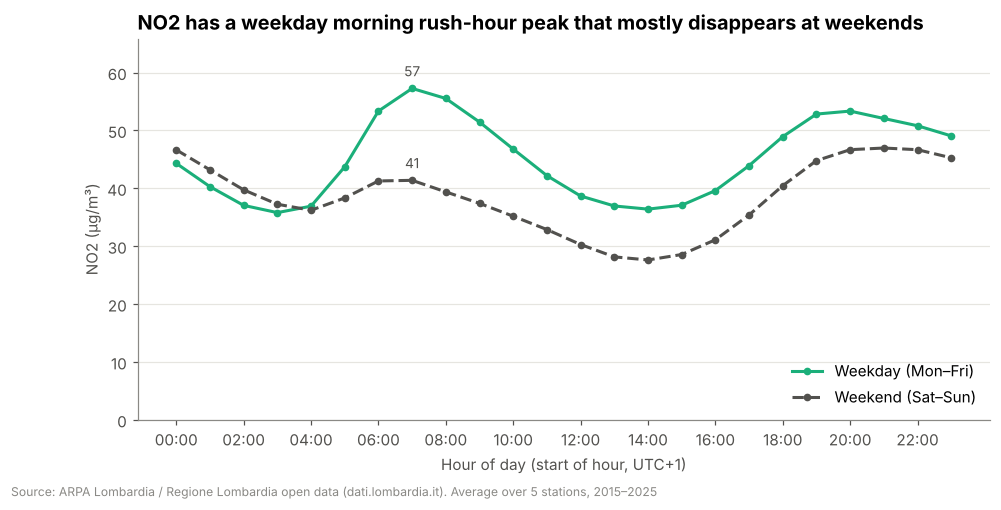

In [11]:
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(profile.index, profile["Weekday"], color=COLORS["NO2"], marker="o", ms=4, label="Weekday (Mon–Fri)")
ax.plot(profile.index, profile["Weekend"], color=GREY, marker="o", ms=4, ls="--", label="Weekend (Sat–Sun)")
for col, c in [("Weekday", COLORS["NO2"]), ("Weekend", GREY)]:
    h = profile[col].loc[5:11].idxmax()
    ax.annotate(f"{profile[col][h]:.0f}", (h, profile[col][h]), textcoords="offset points", xytext=(0, 8), ha="center", color=GREY, fontsize=9)
ax.set_xticks(range(0, 24, 2), [f"{h:02d}:00" for h in range(0, 24, 2)])
ax.set_ylabel(f"NO2 ({UNIT})")
ax.set_xlabel("Hour of day (start of hour, UTC+1)")
ax.set_ylim(0, profile.max().max() * 1.15)
ax.set_title("NO2 has a weekday morning rush-hour peak that mostly disappears at weekends")
ax.legend(loc="lower right")
add_source(fig, "Average over 5 stations, 2015–2025")
save(fig, "04_no2_daily_cycle")
plt.show()

The two-peak shape follows traffic: a morning rush-hour peak, and an evening rise when traffic returns and the air near the ground becomes stable again after sunset. At weekends the morning peak is much smaller (about 41 vs 57 µg/m³).

## 5. Comparison with WHO guidelines

The WHO 2021 guidelines (µg/m³):

| | Annual mean | 24-hour (should be exceeded on ≤ 3–4 days/year) |
|---|---|---|
| PM10 | 15 | 45 |
| PM2.5 | 5 | 15 |
| NO2 | 10 | 25 |

These are health-based targets, much stricter than the legal EU limits that applied in this period (annual PM10 40, PM2.5 25, NO2 40; PM10 daily 50 on at most 35 days/year).

In [12]:
ratio_who = (annual / pd.Series(WHO_ANNUAL)).round(1)
ratio_who.loc[[2015, 2020, 2025]]

,PM10,PM2.5,NO2
date,,,
2015,2.7,6.1,5.9
2020,2.2,4.8,3.9
2025,1.7,3.9,3.2


In [13]:
days_over = pd.DataFrame({p: (city[p] > WHO_DAILY[p]).groupby(city.index.year).sum() for p in POLLUTANTS})
valid_days = city.notna().groupby(city.index.year).sum()
days_over

,PM10,PM2.5,NO2
date,,,
2015,116,246,360
2016,81,214,363
2017,114,182,350
2018,81,200,349
2019,72,169,322
2020,89,200,271
2021,68,171,289
2022,86,192,288
2023,43,173,261


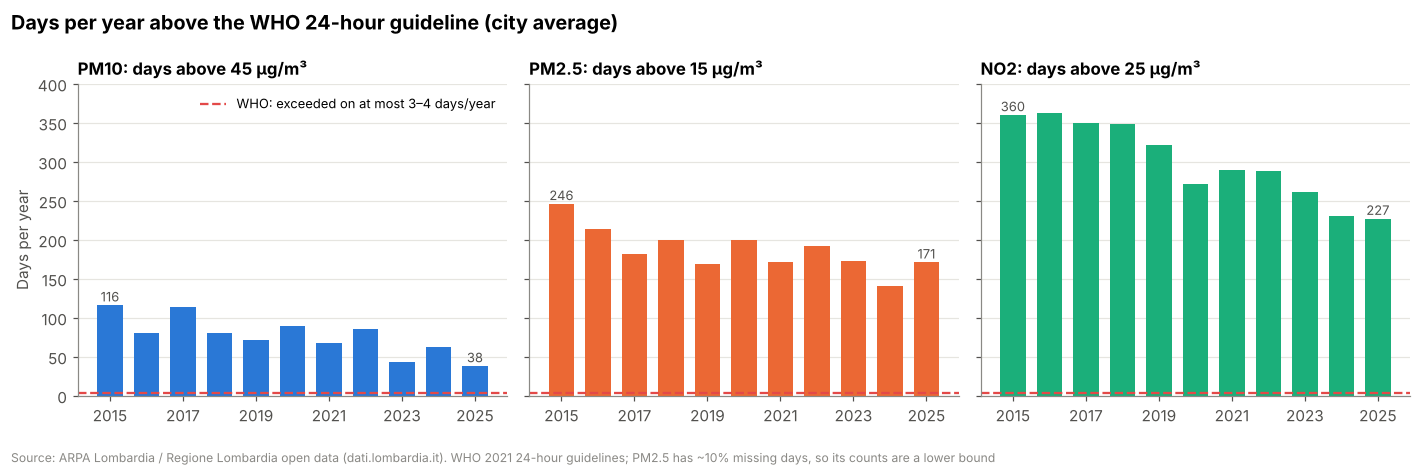

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
for ax, p in zip(axes, POLLUTANTS):
    ax.bar(days_over.index, days_over[p], color=COLORS[p], width=0.7)
    ax.axhline(4, color=WHO_COLOR, ls="--", lw=1.5)
    ax.set_title(f"{p}: days above {WHO_DAILY[p]} {UNIT}", loc="left", fontsize=11)
    ax.set_xticks(range(2015, 2026, 2))
    for yr in (2015, 2025):
        ax.text(yr, days_over.loc[yr, p] + 5, int(days_over.loc[yr, p]), ha="center", fontsize=8.5, color=GREY)
axes[0].set_ylabel("Days per year")
axes[0].plot([], [], color=WHO_COLOR, ls="--", lw=1.5, label="WHO: exceeded on at most 3–4 days/year")
axes[0].legend(loc="upper right", fontsize=8.5)
for ax in axes:
    ax.set_ylim(0, 400)
fig.suptitle("Days per year above the WHO 24-hour guideline (city average)", x=0.01, ha="left", fontweight="bold", fontsize=13)
fig.tight_layout()
add_source(fig, "WHO 2021 24-hour guidelines; PM2.5 has ~10% missing days, so its counts are a lower bound")
save(fig, "05_who_exceedance_days")
plt.show()

### The legal EU limit for PM10 (per station)

The EU rule is checked per station, not on a city average: a station may exceed 50 µg/m³ on at most 35 days per year.

In [15]:
pm10 = station[station["pollutant"] == "PM10"]
eu_days = (pm10.assign(year=pm10["date"].dt.year, over=pm10["valore"] > EU_PM10_DAILY_LIMIT)
               .groupby(["year", "station"])["over"].sum().unstack())
eu_days

station,Milano Pascal Città Studi,Milano Verziere,Milano v.Senato
year,,,
2015,100,91,101
2016,73,58,61
2017,92,82,97
2018,52,59,64
2019,50,46,67
2020,65,56,90
2021,52,30,61
2022,52,44,84
2023,34,14,49


## Summary

The numbers below are taken from the cells above.

- **Trend:** all three pollutants declined consistently from 2015 to 2025 (Theil–Sen, Kendall p < 0.01). NO2 fell fastest (about −2.6 µg/m³ per year, about −45% between the annual means of 2015 and 2025). PM10 and PM2.5 fell by about a third.
- **Still far from WHO:** in 2025 the annual mean was about 1.7× the WHO guideline for PM10, about 3.9× for PM2.5 and about 3.2× for NO2.
- **Seasonality dominates:** January PM2.5 is about 3.5× the May level; this is the Po Valley's winter stagnation.
- **Human activity cycles:** NO2 is about 19% below its weekly mean on Sundays, and has a weekday morning rush-hour peak, which points to traffic. PM's weekly cycle is weaker.
- **Legal compliance improved but is not reached:** PM10 days above the EU 50 µg/m³ limit fell from 91–101 per station in 2015 to 21–36 in 2025. Still, in no year did all three stations stay within the 35 allowed days (Pascal Città Studi had 36 in 2025).